# 卷积神经网络

为什么要用CNN？
1. 参数过多：对图像来说，每个像素点都是一个输入，如果用全连接前馈神经网络，会导致参数过多，训练效率差、容易过拟合。
2. 局部不变性特征：对图像数据来说，图像里某个有意义的局部模式，即使位置发生一定变化，它所表达的语义通常不变。CNN 正好利用这个特点：
- 局部连接：每次只看一小块区域；
- 权重共享：同一个卷积核在整张图上滑，所以同一种特征出现在不同位置都能检测到；
- 池化：对小范围位置变化没那么敏感。

## 卷积

滑动步长$S$，零填充$P$（$P=n$表示输入向量边缘补几个0）

等宽卷积：一维：步长$S=1$，零填充$P=\dfrac{F-1}{2}$，卷积后输出长度为$M$(输入的大小)

**二维卷积**：$输出尺寸=\left\lfloor \dfrac{N-F+2P}{S}\right\rfloor + 1$（stride=1，F为奇数）

其中$N$是图像尺寸（宽、高），$F$是卷积核尺寸，$P$是零填充宽度，$S$是步长。

$CNN=局部连接+权重共享+池化$

1. 为什么卷积比全连接参数小？***答：*** 卷积通过局部连接和权重共享减少参数。
2. 为什么同一个卷积核要在整张图上滑？***答：*** 同一卷积核在全图滑动，是为了在不同位置检测相同的局部特征。
3. 最大池化/平均池化（max pooling/mean pooling）在干什么，为什么能降维并增强一定的局部不变性？***答：*** 池化对局部特征进行最大值或平均值汇总，降低特征图尺寸；当特征在池化区域内发生小幅移动时，池化结果可能保持不变或变化较小，因此增强一定的局部不变性。

## 卷积神经网络

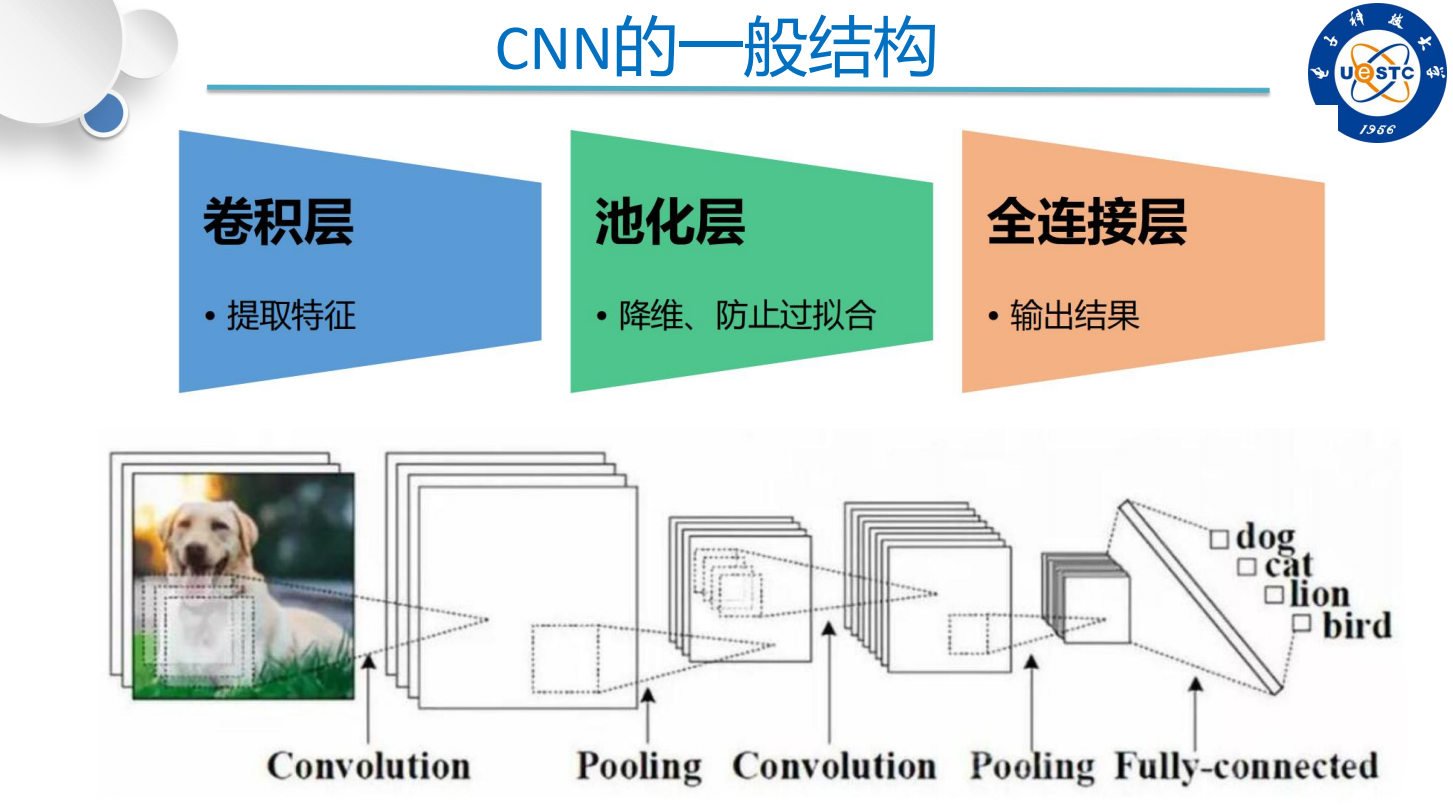

一个卷积层通常同时有很多个卷积核，每个卷积核在整张输入上滑动，各自产生一张特征图。

1. 3通道卷积，指的是卷积计算的时候同时处理3个***输入通道***，即卷积核尺寸为$F_h\times F_w\times C_{\text{in}}$。最终加权求和得到一个标量。
2. 每个卷积核最终得到一张特征图，特征图的数量称为***输出通道***。
3. 池化不减少特征图的数量，会减小特征图的空间尺寸

**CNN参数量：**
$F_hF_wC_{in}C_{out}+C_{out}$，最后一个$C_{out}$是偏置$bias$的数量，因为通常一个卷积核有一个$bias$

## 二维卷积练习

In [1]:
import numpy as np

In [2]:
rng = np.random.default_rng(seed=42)

# 生成矩阵
def gen_mats(source_size, kernel_size):
    source = rng.integers(0, 10, source_size)
    kernel = rng.integers(0, 2, kernel_size)
    return source, kernel
#理论维度
def dim(source, kernel, padding, stride):
    import math
    height = math.floor((source.shape[0] - kernel.shape[0] + 2 * padding) / stride) + 1
    width = math.floor((source.shape[1] - kernel.shape[1] + 2 * padding) / stride) + 1
    return height, width

In [3]:
def conv(source_size, kernel_size, *, padding, stride):
    source, kernel = gen_mats(source_size, kernel_size)
    padded = np.pad(source, pad_width=((padding, padding), (padding, padding)), mode='constant')
    print(source)
    if padding != 0:
        print(padded)
    
    #source = pad_source(source)
    sh, sw = source.shape # 原图的高和宽
    ph, pw = padded.shape # 填充后
    kh, kw = kernel.shape # 卷积核
    print(f"source-size={sh}x{sw},", end="")
    if padding != 0:
        print(f"padded-size={ph}x{pw},", end="")
    print(f"kernel-size={kh}x{kw}")

    res = []
    for i in range(0, ph - kh + 1, stride):
        res.append([])
        for j in range(0, pw - kw + 1, stride):
            val = int(np.sum(kernel * padded[i:i + kh, j:j + kw]))
            if i == 0 and j == 0:
                print(f"conv[0][0]={val}")
            res[-1].append(val)
    resnp = np.array(res)
    print(resnp, resnp.shape)
    print(f"理论feature map大小:{dim(source, kernel, padding, stride)}\n------")

In [4]:
conv((5, 5), (3, 3), padding=0, stride=1)
conv((5, 5), (3, 3), padding=1, stride=1)
conv((7, 4), (3, 2), padding=0, stride=1)
conv((20, 18), (6, 4), padding=2, stride=2)

[[0 7 6 4 4]
 [8 0 6 2 0]
 [5 9 7 7 7]
 [7 5 1 8 4]
 [5 3 1 9 7]]
source-size=5x5,kernel-size=3x3
conv[0][0]=21
[[21 18 23]
 [20 19 17]
 [20 30 22]] (3, 3)
理论feature map大小:(3, 3)
------
[[8 0 8 8 2]
 [6 1 7 7 3]
 [0 9 4 8 6]
 [7 7 1 3 4]
 [4 0 5 1 7]]
[[0 0 0 0 0 0 0]
 [0 8 0 8 8 2 0]
 [0 6 1 7 7 3 0]
 [0 0 9 4 8 6 0]
 [0 7 7 1 3 4 0]
 [0 4 0 5 1 7 0]
 [0 0 0 0 0 0 0]]
source-size=5x5,padded-size=7x7,kernel-size=3x3
conv[0][0]=14
[[14  1 15 15  5]
 [14 26 27 33 19]
 [14 30 20 28 20]
 [20 20 27 22 25]
 [18 15 16  9 14]] (5, 5)
理论feature map大小:(5, 5)
------
[[0 4 7 1]
 [4 1 6 4]
 [3 2 5 6]
 [9 4 1 8]
 [6 7 0 3]
 [7 8 4 8]
 [8 3 8 2]]
source-size=7x4,kernel-size=3x2
conv[0][0]=11
[[11 10 12]
 [13 12 10]
 [17 16  7]
 [17 16 12]
 [22 11 15]] (5, 3)
理论feature map大小:(5, 3)
------
[[8 0 7 7 7 6 4 7 2 7 5 4 5 5 0 1 2 1]
 [4 6 6 4 8 5 0 7 5 6 5 5 0 5 7 3 6 0]
 [3 4 9 2 2 4 9 8 0 2 8 0 8 2 9 2 4 6]
 [1 5 5 7 9 6 4 4 4 8 3 1 3 0 1 0 7 7]
 [6 4 7 1 9 5 9 1 4 6 4 4 1 3 2 3 6 6]
 [6 3 9 0 3 1 3 9 3 9